### Nama : M. Padil Mangulele
### Nim :  H061241071
# Tugas 2: Implementasi Prompt R–T–C–I–K–O–Q–V pada Lima Studi Kasus Geofisika
##  Tugas 2   berikan kelima output (Modul Prompt AI yang Terukur untuk Analisis Geofisika)


## 1. Pendahuluan

Pada **Tugas 1** saya mempelajari framework **R–T–C–I–K–O–Q–V** dan membuktikannya pada satu kasus: seismik refraksi dua lapis, lengkap dengan perhitungan pembanding (komponen *Verification*). Tugas 2 ini melanjutkannya: lima contoh prompt dijalankan, lalu **keluarannya dihasilkan dan saya interpretasikan sendiri**.

Prinsip yang saya pertahankan dari Tugas 1:

- Prompt diperlakukan sebagai **spesifikasi kerja**, jadi setiap prompt ditulis lengkap dengan format `### Role` sampai `### Optional Verification`.
- Prompt diuji dengan fungsi `cek_prompt()` yang sama seperti di Tugas 1.
- Data pada modul ini adalah **data sintetis/ilustrasi**, bukan data lapangan. Karena modelnya dibuat sendiri, hasil deteksi dapat **diverifikasi terhadap model sebenarnya**.
- Tiap studi kasus memuat: prompt, keluaran (tabel dan grafik), verifikasi, lalu interpretasi **maksimal 5 kalimat** disertai keterbatasan, sesuai ketentuan *Output* pada prompt Tugas 1.
- Kasus seismik refraksi memakai **data yang sama persis dengan Tugas 1**, sehingga hasilnya dapat dicocokkan langsung (V1 = 500 m/s, V2 = 1000 m/s, xc = 13 m, z = 3,75 m).

| No | Studi Kasus | Metode / Keluaran utama |
|:--:|:------------|:------------------------|
| 1 | Geolistrik | Penampang resistivitas 2D |
| 2 | DInSAR | Interferogram dan displacement LOS |
| 3 | InSAR Time Series | Velocity map dan deret waktu |
| 4 | Seismik Refraksi | Kurva jarak-waktu dan model dua lapis |
| 5 | Gravitasi | Anomali Bouguer dan gradien horizontal |

> **Catatan:** setiap sel dapat dijalankan ulang dari atas ke bawah. Seed acak diturunkan dari NIM, sehingga angka selalu sama.

## 2. Persiapan

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from scipy import ndimage
from scipy.ndimage import gaussian_filter

plt.rcParams.update({"font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10,
                     "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

NAMA, NIM = "M. Padil Mangulele", "H061241071"
SEED_DASAR = 1241071            # diambil dari NIM agar hasil selalu sama (reproducible)

# ---- Pengecek kelengkapan prompt (sama dengan Tugas 1, ditambah nilai kembalian) ----
KOMPONEN = {
    "R": ["role", "peran", "bertindak sebagai", "anda adalah"],
    "T": ["task", "tugas"],
    "C": ["context", "konteks", "latar belakang"],
    "I": ["input", "data"],
    "K": ["constraint", "batasan", "dilarang", "tidak boleh"],
    "O": ["output", "keluaran", "format"],
    "Q": ["quality", "kriteria"],
    "V": ["verification", "verifikasi"],
}

def cek_prompt(teks, tampil=True):
    teks_kecil = teks.lower()
    hasil = {k: any(re.search(re.escape(w), teks_kecil) for w in kw) for k, kw in KOMPONEN.items()}
    wajib = ["R", "T", "C", "I", "K", "O", "Q"]          # V bersifat opsional
    skor = sum(hasil[k] for k in wajib)
    if tampil:
        print(f"Skor komponen wajib: {skor}/{len(wajib)}   |   Verification (opsional): {'ada' if hasil['V'] else 'tidak ada'}")
        print("Komponen:", "  ".join(f"[{k}] {'ada' if v else 'TIDAK ADA'}" for k, v in hasil.items()))
    return skor, hasil["V"]

REKAP_PROMPT = {}   # diisi tiap studi kasus, dipakai di bagian rekap
print("Library siap. Seed dasar:", SEED_DASAR)

Library siap. Seed dasar: 1241071


---
# STUDI KASUS 1: GEOLISTRIK
## Interpretasi Penampang Resistivitas 2D

### Prompt (R–T–C–I–K–O–Q–V) dan uji kelengkapan

In [2]:
prompt_1 = """
### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil pengukuran geolistrik
konfigurasi 2D untuk investigasi air tanah dangkal.

### Task
Interpretasikan penampang resistivitas 2D hasil inversi: tentukan pola resistivitas,
pembagian lapisan, kemungkinan material, dan zona anomali.

### Context
Perbedaan resistivitas mencerminkan perbedaan material dan kondisi geologi (litologi,
kadar air, salinitas). Lintasan 200 m (41 elektroda, spasi 5 m), kedalaman model 40 m.

### Input
Penampang resistivitas 2D (ohm.m terhadap jarak dan kedalaman), skala warna logaritmik,
dan informasi geologi umum: daerah endapan dengan dugaan akuifer dangkal.

### Constraints
- Dilarang mengolah ulang data atau membuat nilai resistivitas baru.
- Gunakan hanya nilai, satuan, dan legenda yang tampil pada penampang.
- Rentang resistivitas yang saling tumpang tindih tidak boleh dipakai untuk memastikan jenis batuan.
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapat ditentukan".

### Output
1. Tabel zona resistivitas (rentang, kedalaman, kemungkinan material)
2. Zona anomali beserta posisi dan dimensinya
3. Interpretasi singkat (maksimal 5 kalimat) dan daftar keterbatasan

### Quality Criteria
- Interpretasi sesuai dengan penampang, angka dapat ditelusuri ke gambar.
- Bahasa mudah dipahami; pengamatan dibedakan dari dugaan.

### Optional Verification
Cocokkan interpretasi dengan penampang dan informasi geologi; konfirmasi akuifer
dengan data sumur bor.
"""
print(prompt_1)
print("-" * 70)
REKAP_PROMPT["1. Geolistrik"] = cek_prompt(prompt_1)


### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil pengukuran geolistrik
konfigurasi 2D untuk investigasi air tanah dangkal.

### Task
Interpretasikan penampang resistivitas 2D hasil inversi: tentukan pola resistivitas,
pembagian lapisan, kemungkinan material, dan zona anomali.

### Context
Perbedaan resistivitas mencerminkan perbedaan material dan kondisi geologi (litologi,
kadar air, salinitas). Lintasan 200 m (41 elektroda, spasi 5 m), kedalaman model 40 m.

### Input
Penampang resistivitas 2D (ohm.m terhadap jarak dan kedalaman), skala warna logaritmik,
dan informasi geologi umum: daerah endapan dengan dugaan akuifer dangkal.

### Constraints
- Dilarang mengolah ulang data atau membuat nilai resistivitas baru.
- Gunakan hanya nilai, satuan, dan legenda yang tampil pada penampang.
- Rentang resistivitas yang saling tumpang tindih tidak boleh dipakai untuk memastikan jenis batuan.
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapat ditentukan".

### O

### Keluaran, verifikasi, dan grafik

Lintasan 200 m | grid 161 x 81 | rho: min 6.1, median 510.3, maks 2654 ohm.m

ZONA ANOMALI (ambang dari nilai penampang)
              Anomali     x (m)       z (m) pusat (x, z) rho min/maks (ohm.m) luas (m2)
  Rendah (< 20 ohm.m)   70 - 90  7.5 - 12.5    (80, 9.9)             6.1 / 20        89
Tinggi (> 1200 ohm.m) 151 - 168 22.5 - 32.0  (159, 27.3)        1205.1 / 2654       140

BATAS LAPISAN dari profil di x = 30 m (gradien maksimum)
  Zona Kedalaman (m) rho median (ohm.m)
  Atas       0 - 5.5                 45
Tengah    5.5 - 19.5                179
 Bawah        > 19.5                684

VERIFIKASI terhadap model sintetis
  Batas 1-2 : terdeteksi 5.5 m | model 5.8 m
  Batas 2-3 : terdeteksi 19.5 m | model 19.2 m
  Pusat anomali rendah : terdeteksi (80, 9.9) | model (80, 10)
  Pusat anomali tinggi : terdeteksi (159, 27.3) | model (160, 27)


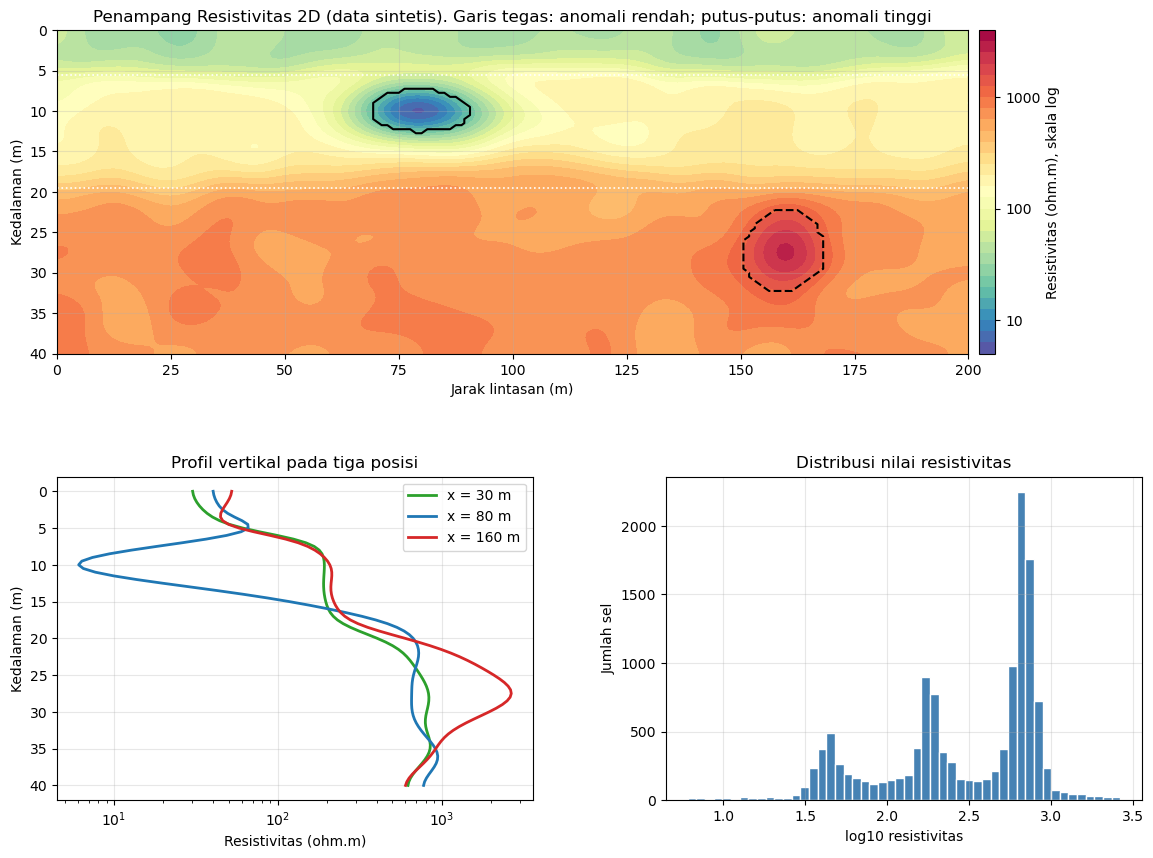

In [3]:
# ---------------- DATA SINTETIS: penampang resistivitas 2D ----------------
rng = np.random.default_rng(SEED_DASAR + 1)
n_elek, spasi = 41, 5.0
L = (n_elek - 1) * spasi                         # 200 m
x = np.linspace(0, L, 161)                       # m
z = np.linspace(0, 40, 81)                       # m
X, Z = np.meshgrid(x, z)

sig = lambda a: 1 / (1 + np.exp(-a))
z1 = 5 + 0.8 * np.sin(2 * np.pi * X / 120)             # batas lapisan 1-2 (sedikit bergelombang)
z2 = 18 + 1.5 * np.sin(2 * np.pi * X / 160 + 1.0)      # batas lapisan 2-3
lg = (np.log10(40) + (np.log10(180) - np.log10(40)) * sig((Z - z1) / 0.8)
      + (np.log10(700) - np.log10(180)) * sig((Z - z2) / 1.2))

w_aku  = np.exp(-(((X - 80) / 16) ** 2 + ((Z - 10) / 4) ** 2))     # zona jenuh air
w_blok = np.exp(-(((X - 160) / 10) ** 2 + ((Z - 27) / 6) ** 2))    # tubuh resistif
lg = lg + w_aku * (np.log10(8) - lg) + w_blok * (np.log10(2500) - lg)
derau = gaussian_filter(rng.normal(size=X.shape), 4); derau = derau / derau.std() * 0.05
rho = 10 ** (lg + derau)                          # ohm.m

print(f"Lintasan {L:.0f} m | grid {len(x)} x {len(z)} | rho: min {rho.min():.1f}, "
      f"median {np.median(rho):.1f}, maks {rho.max():.0f} ohm.m")

# ---------------- OUTPUT: deteksi anomali dari nilai pada penampang ----------------
def anomali(mask, nama):
    lab, n = ndimage.label(mask)
    if n == 0:
        return None
    ukuran = ndimage.sum(mask, lab, range(1, n + 1))
    k = np.argmax(ukuran) + 1
    m = lab == k
    return {"Anomali": nama, "x (m)": f"{X[m].min():.0f} - {X[m].max():.0f}",
            "z (m)": f"{Z[m].min():.1f} - {Z[m].max():.1f}",
            "pusat (x, z)": f"({X[m].mean():.0f}, {Z[m].mean():.1f})",
            "rho min/maks (ohm.m)": f"{rho[m].min():.1f} / {rho[m].max():.0f}",
            "luas (m2)": f"{m.sum() * (x[1] - x[0]) * (z[1] - z[0]):.0f}"}, m

a_rendah, m_rendah = anomali(rho < 20, "Rendah (< 20 ohm.m)")
a_tinggi, m_tinggi = anomali(rho > 1200, "Tinggi (> 1200 ohm.m)")
print("\nZONA ANOMALI (ambang dari nilai penampang)")
print(pd.DataFrame([a_rendah, a_tinggi]).to_string(index=False))

# ---------------- OUTPUT: batas lapisan dari profil vertikal di x = 30 m (di luar anomali) ----------------
i30 = np.argmin(abs(x - 30))
prof = np.log10(rho[:, i30])
turun = np.gradient(gaussian_filter(prof, 1.5), z)
b1 = z[(z > 2) & (z < 11)][np.argmax(turun[(z > 2) & (z < 11)])]
b2 = z[(z > 11) & (z < 30)][np.argmax(turun[(z > 11) & (z < 30)])]
lap = pd.DataFrame({
    "Zona": ["Atas", "Tengah", "Bawah"],
    "Kedalaman (m)": [f"0 - {b1:.1f}", f"{b1:.1f} - {b2:.1f}", f"> {b2:.1f}"],
    "rho median (ohm.m)": [f"{np.median(rho[(Z < b1)]):.0f}", f"{np.median(rho[(Z >= b1) & (Z < b2)]):.0f}",
                           f"{np.median(rho[Z >= b2]):.0f}"],
})
print("\nBATAS LAPISAN dari profil di x = 30 m (gradien maksimum)")
print(lap.to_string(index=False))

# ---------------- VERIFIKASI: bandingkan dengan model sintetis (kunci jawaban) ----------------
print("\nVERIFIKASI terhadap model sintetis")
print(f"  Batas 1-2 : terdeteksi {b1:.1f} m | model {z1[0, i30]:.1f} m")
print(f"  Batas 2-3 : terdeteksi {b2:.1f} m | model {z2[0, i30]:.1f} m")
print(f"  Pusat anomali rendah : terdeteksi ({X[m_rendah].mean():.0f}, {Z[m_rendah].mean():.1f}) | model (80, 10)")
print(f"  Pusat anomali tinggi : terdeteksi ({X[m_tinggi].mean():.0f}, {Z[m_tinggi].mean():.1f}) | model (160, 27)")

# ---------------- VISUALISASI ----------------
fig = plt.figure(figsize=(14, 10)); gs = GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.28)
ax = fig.add_subplot(gs[0, :])
im = ax.contourf(X, Z, np.log10(rho), levels=np.linspace(0.7, 3.6, 30), cmap="Spectral_r")
cb = plt.colorbar(im, ax=ax, pad=0.01, ticks=[1, 2, 3]); cb.ax.set_yticklabels(["10", "100", "1000"])
cb.set_label("Resistivitas (ohm.m), skala log")
ax.contour(X, Z, m_rendah.astype(float), levels=[0.5], colors="k", linewidths=1.5)
ax.contour(X, Z, m_tinggi.astype(float), levels=[0.5], colors="k", linewidths=1.5, linestyles="--")
ax.axhline(b1, color="w", ls=":", lw=1.2); ax.axhline(b2, color="w", ls=":", lw=1.2)
ax.invert_yaxis(); ax.set_xlabel("Jarak lintasan (m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title("Penampang Resistivitas 2D (data sintetis). Garis tegas: anomali rendah; putus-putus: anomali tinggi")

ax = fig.add_subplot(gs[1, 0])
for xp, c in [(30, "tab:green"), (80, "tab:blue"), (160, "tab:red")]:
    ax.semilogx(rho[:, np.argmin(abs(x - xp))], z, color=c, lw=2, label=f"x = {xp} m")
ax.invert_yaxis(); ax.set_xlabel("Resistivitas (ohm.m)"); ax.set_ylabel("Kedalaman (m)")
ax.set_title("Profil vertikal pada tiga posisi"); ax.legend()

ax = fig.add_subplot(gs[1, 1])
ax.hist(np.log10(rho).ravel(), bins=50, color="steelblue", edgecolor="white")
ax.set_xlabel("log10 resistivitas"); ax.set_ylabel("Jumlah sel"); ax.set_title("Distribusi nilai resistivitas")
plt.show()

### Interpretasi (ditulis sendiri berdasarkan keluaran di atas)

**Pengamatan dan dugaan:**
Penampang memperlihatkan tiga zona bertingkat yang resistivitasnya naik terhadap kedalaman: zona atas (0–5,5 m, median 45 ohm.m), zona tengah (5,5–19,5 m, median 179 ohm.m), dan zona bawah (> 19,5 m, median 684 ohm.m), yang secara umum cocok dengan dugaan tanah penutup lembap, material sedimen/pasir, lalu material kompak di bawahnya. Pada x = 70–90 m dan kedalaman 7,5–12,5 m terdapat anomali resistivitas rendah (minimum 6,1 ohm.m) yang jauh di bawah sekitarnya (sekitar 180 ohm.m), sehingga **diduga** zona jenuh air yang berpotensi akuifer. Pada x = 151–168 m dan kedalaman 22,5–32 m terdapat anomali resistivitas tinggi (hingga 2654 ohm.m) yang **diduga** tubuh yang lebih kompak dari sekitarnya. Jenis batuan pasti, serta apakah anomali rendah berupa air tanah atau lempung jenuh, **tidak dapat ditentukan** hanya dari nilai resistivitas.

**Verifikasi:** batas lapisan terdeteksi 5,5 dan 19,5 m terhadap model 5,8 dan 19,2 m (selisih 0,3 m); pusat kedua anomali meleset paling jauh 1 m dari model. Pada data nyata, dugaan akuifer harus dikonfirmasi dengan data sumur bor.

**Keterbatasan:** (1) rentang resistivitas berbagai material saling tumpang tindih; (2) dimensi anomali bergantung pada ambang yang dipilih (20 dan 1200 ohm.m); (3) data sintetis tanpa efek ekuivalensi dan kedalaman investigasi inversi nyata.

---
# STUDI KASUS 2: DInSAR
## Deformasi Permukaan dari Interferogram dan Peta Displacement

### Prompt (R–T–C–I–K–O–Q–V) dan uji kelengkapan

In [4]:
prompt_2 = """
### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil DInSAR (Differential
Interferometric SAR) untuk studi deformasi permukaan.

### Task
Interpretasikan pola deformasi permukaan pada interferogram dan peta displacement:
wilayah deformasi, besar, arah perubahan, dan kemungkinan penyebabnya.

### Context
DInSAR mendeteksi perubahan permukaan dari dua waktu pengamatan. Satu siklus warna
(fringe) pada citra C-band (panjang gelombang 5,55 cm) setara 2,775 cm perubahan jarak
sepanjang LOS (line of sight). Displacement positif = permukaan mendekati satelit.

### Input
Interferogram (wrapped phase, radian), peta displacement LOS (cm), area 70 km x 60 km,
informasi: terjadi gempa dangkal di wilayah studi di antara dua akuisisi.

### Constraints
- Dilarang mengolah ulang data (tidak unwrapping ulang, tidak koreksi tambahan).
- Tidak semua perubahan warna adalah deformasi; bedakan sinyal dari atmosfer/derau.
- Bedakan secara tegas antara pengamatan dan dugaan penyebab.
- Jika data tidak mendukung suatu kesimpulan (misalnya mekanisme sesar), tulis "tidak dapat ditentukan".

### Output
1. Tabel wilayah deformasi (posisi, arah, nilai maksimum)
2. Jumlah fringe dan pemeriksaannya terhadap nilai displacement
3. Interpretasi singkat (maksimal 5 kalimat) dan daftar keterbatasan

### Quality Criteria
- Interpretasi berbasis hasil yang tampil; satuan konsisten (cm, radian, km).
- Dugaan penyebab diberi tanda sebagai dugaan, bukan fakta.

### Optional Verification
Bandingkan dengan katalog gempa (BMKG/USGS), data GNSS, dan peta geologi.
"""
print(prompt_2)
print("-" * 70)
REKAP_PROMPT["2. DInSAR"] = cek_prompt(prompt_2)


### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil DInSAR (Differential
Interferometric SAR) untuk studi deformasi permukaan.

### Task
Interpretasikan pola deformasi permukaan pada interferogram dan peta displacement:
wilayah deformasi, besar, arah perubahan, dan kemungkinan penyebabnya.

### Context
DInSAR mendeteksi perubahan permukaan dari dua waktu pengamatan. Satu siklus warna
(fringe) pada citra C-band (panjang gelombang 5,55 cm) setara 2,775 cm perubahan jarak
sepanjang LOS (line of sight). Displacement positif = permukaan mendekati satelit.

### Input
Interferogram (wrapped phase, radian), peta displacement LOS (cm), area 70 km x 60 km,
informasi: terjadi gempa dangkal di wilayah studi di antara dua akuisisi.

### Constraints
- Dilarang mengolah ulang data (tidak unwrapping ulang, tidak koreksi tambahan).
- Tidak semua perubahan warna adalah deformasi; bedakan sinyal dari atmosfer/derau.
- Bedakan secara tegas antara pengamatan dan dugaan penyebab.
- Jika d

### Keluaran, verifikasi, dan grafik

Panjang gelombang 5.55 cm -> 1 fringe = 2.775 cm LOS
Derau kotak referensi (0-12 km): std = 0.17 cm -> ambang sinyal (3 sigma) = 0.52 cm

WILAYAH DEFORMASI (komponen terhubung di atas ambang derau yang memuat puncak)
              Wilayah Posisi puncak (E, N km) Nilai ekstrem (cm) Luas lobus (km2)
Mendekati satelit (+)                (28, 30)               +8.6              771
 Menjauhi satelit (-)                (44, 34)               -3.4              265
Area di atas ambang yang TIDAK terhubung ke kedua lobus: 721 km2 (kandidat atmosfer/derau, tidak dihitung sebagai deformasi)
Lobus (-) terhadap lobus (+): +16 km ke timur, +5 km ke utara

VERIFIKASI fringe pada profil y = 32 km:
  dari fase (unwrap pada profil)      : 4.38 fringe
  dari displacement / (lambda/2)      : 4.38 fringe
  kontribusi atmosfer pada profil ini : 0.62 fringe (kunci jawaban; BUKAN deformasi)
  gradien atmosfer seluruh area       : 2.0 cm = 0.73 fringe
VERIFIKASI nilai ekstrem: sinyal sebenarnya +8.8 / -4.4 cm

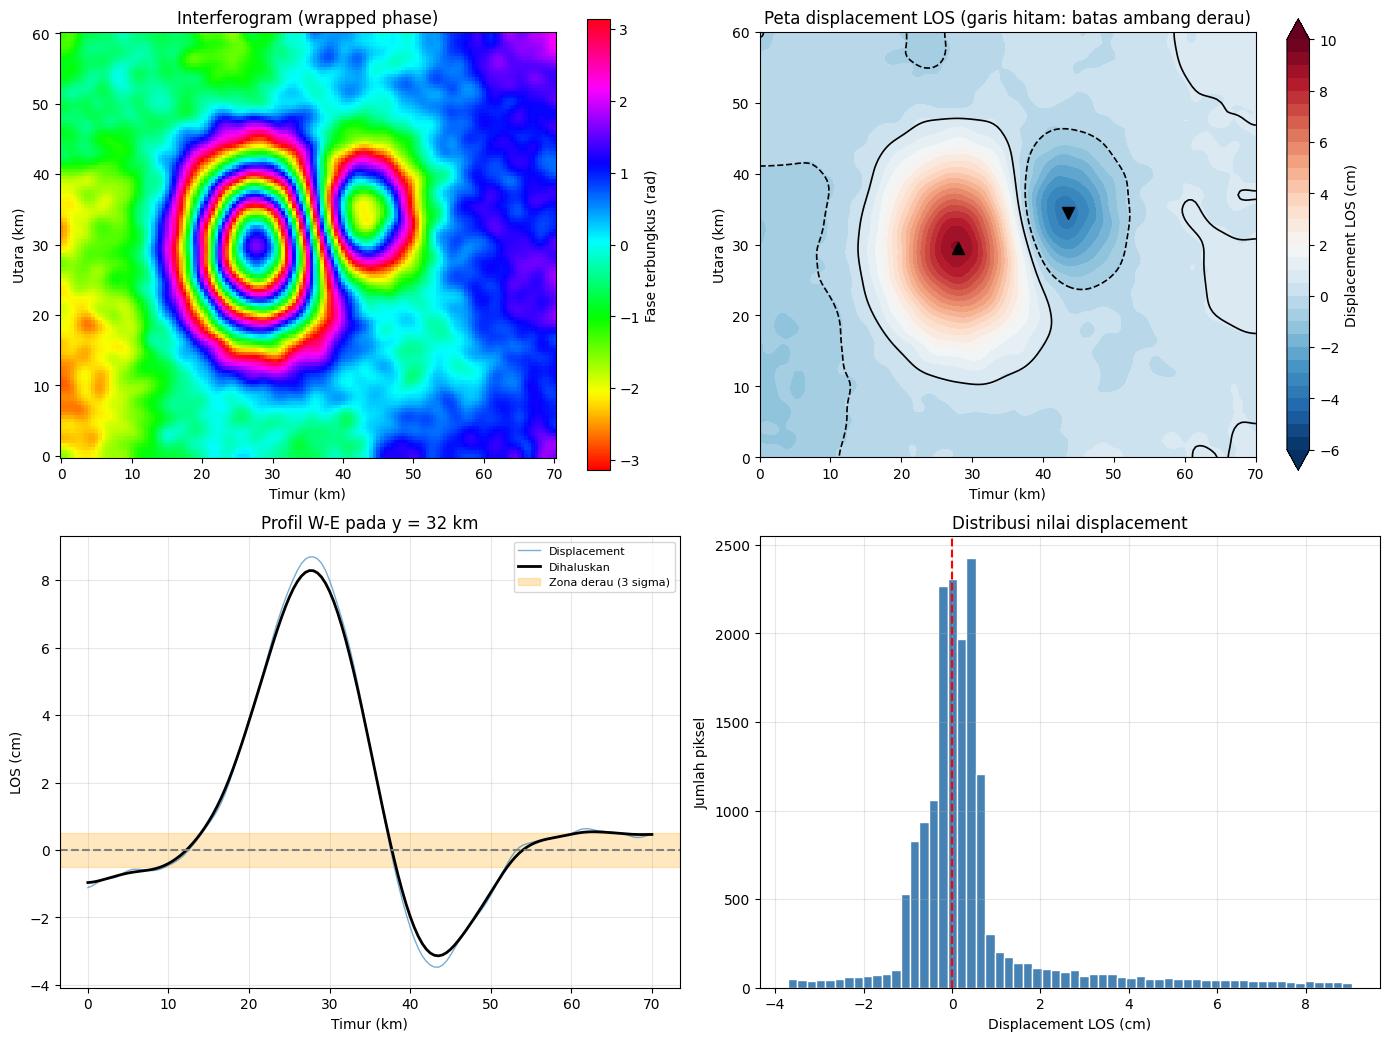

In [5]:
# ---------------- DATA SINTETIS: displacement LOS dan interferogram ----------------
rng = np.random.default_rng(SEED_DASAR + 2)
lam = 5.55                                        # cm (C-band, Sentinel-1)
nx, ny = 141, 121
xk = np.linspace(0, 70, nx); yk = np.linspace(0, 60, ny)     # km (x = timur, y = utara)
Xk, Yk = np.meshgrid(xk, yk)

d_naik  =  9.0 * np.exp(-(((Xk - 28) / 9) ** 2 + ((Yk - 30) / 12) ** 2))   # menuju satelit
d_turun = -5.0 * np.exp(-(((Xk - 42) / 8) ** 2 + ((Yk - 34) / 9) ** 2))    # menjauhi satelit
d_sinyal = d_naik + d_turun

# atmosfer: gradien lembut + turbulensi (BUKAN deformasi), plus derau kecil
aps = 1.2 * (Xk / 70) + gaussian_filter(rng.normal(size=Xk.shape), 12) * 8
aps = aps - aps.mean()
derau = gaussian_filter(rng.normal(size=Xk.shape), 2) * 0.5
disp = d_sinyal + aps + derau                      # peta displacement LOS (cm)
fase = np.angle(np.exp(1j * (4 * np.pi / lam) * disp))   # wrapped phase (-pi, pi]

# ---------------- OUTPUT: tingkat derau dan wilayah deformasi ----------------
ref = (Xk < 12) & (Yk < 12)                        # kotak jauh dari sumber sebagai pembanding derau
sd_ref = disp[ref].std()
ambang = 3 * sd_ref
print(f"Panjang gelombang {lam} cm -> 1 fringe = {lam/2:.3f} cm LOS")
print(f"Derau kotak referensi (0-12 km): std = {sd_ref:.2f} cm -> ambang sinyal (3 sigma) = {ambang:.2f} cm")

halus = gaussian_filter(disp, 3)
iy, ix = np.unravel_index(halus.argmax(), halus.shape)
jy, jx = np.unravel_index(halus.argmin(), halus.shape)
sig_naik, sig_turun = (halus > ambang), (halus < -ambang)
lab_p, _ = ndimage.label(sig_naik); lab_n, _ = ndimage.label(sig_turun)
lobus_p = lab_p == lab_p[iy, ix]                  # komponen yang memuat puncak (+)
lobus_n = lab_n == lab_n[jy, jx]                  # komponen yang memuat puncak (-)
sisa = (sig_naik | sig_turun) & ~(lobus_p | lobus_n)
luas = lambda m: m.sum() * (xk[1] - xk[0]) * (yk[1] - yk[0])
tabel = pd.DataFrame({
    "Wilayah": ["Mendekati satelit (+)", "Menjauhi satelit (-)"],
    "Posisi puncak (E, N km)": [f"({xk[ix]:.0f}, {yk[iy]:.0f})", f"({xk[jx]:.0f}, {yk[jy]:.0f})"],
    "Nilai ekstrem (cm)": [f"{halus.max():+.1f}", f"{halus.min():+.1f}"],
    "Luas lobus (km2)": [f"{luas(lobus_p):.0f}", f"{luas(lobus_n):.0f}"],
})
print("\nWILAYAH DEFORMASI (komponen terhubung di atas ambang derau yang memuat puncak)")
print(tabel.to_string(index=False))
print(f"Area di atas ambang yang TIDAK terhubung ke kedua lobus: {luas(sisa):.0f} km2 "
      f"(kandidat atmosfer/derau, tidak dihitung sebagai deformasi)")
dE, dN = xk[jx] - xk[ix], yk[jy] - yk[iy]
print(f"Lobus (-) terhadap lobus (+): {dE:+.0f} km ke timur, {dN:+.0f} km ke utara")

# ---------------- VERIFIKASI jumlah fringe: profil W-E melalui kedua lobus ----------------
ip = np.argmin(abs(yk - 32))
profil_fase = np.unwrap(fase[ip, :])
fr_fase = (profil_fase.max() - profil_fase.min()) / (2 * np.pi)
fr_disp = (disp[ip, :].max() - disp[ip, :].min()) / (lam / 2)
fr_atm  = (aps[ip, :].max() - aps[ip, :].min()) / (lam / 2)
print(f"\nVERIFIKASI fringe pada profil y = 32 km:")
print(f"  dari fase (unwrap pada profil)      : {fr_fase:.2f} fringe")
print(f"  dari displacement / (lambda/2)      : {fr_disp:.2f} fringe")
print(f"  kontribusi atmosfer pada profil ini : {fr_atm:.2f} fringe (kunci jawaban; BUKAN deformasi)")
print(f"  gradien atmosfer seluruh area       : {(aps.max()-aps.min()):.1f} cm = {(aps.max()-aps.min())/(lam/2):.2f} fringe")
print(f"VERIFIKASI nilai ekstrem: sinyal sebenarnya {d_sinyal.max():+.1f} / {d_sinyal.min():+.1f} cm | teramati (dihaluskan) {halus.max():+.1f} / {halus.min():+.1f} cm")

# ---------------- VISUALISASI ----------------
fig, ax = plt.subplots(2, 2, figsize=(14, 10.5))
im = ax[0, 0].pcolormesh(Xk, Yk, fase, cmap="hsv", shading="auto", vmin=-np.pi, vmax=np.pi)
plt.colorbar(im, ax=ax[0, 0], label="Fase terbungkus (rad)"); ax[0, 0].set_title("Interferogram (wrapped phase)")
lv = np.linspace(-6, 10, 33)
im = ax[0, 1].contourf(Xk, Yk, disp, levels=lv, cmap="RdBu_r", extend="both")
plt.colorbar(im, ax=ax[0, 1], label="Displacement LOS (cm)")
ax[0, 1].contour(Xk, Yk, halus, levels=[-ambang, ambang], colors="k", linewidths=1.2)
ax[0, 1].plot(xk[ix], yk[iy], "k^", ms=9); ax[0, 1].plot(xk[jx], yk[jy], "kv", ms=9)
ax[0, 1].set_title("Peta displacement LOS (garis hitam: batas ambang derau)")
for a in ax[0]: a.set_xlabel("Timur (km)"); a.set_ylabel("Utara (km)"); a.set_aspect("equal"); a.grid(False)
ax[1, 0].plot(xk, disp[ip, :], color="tab:blue", lw=1, alpha=.6, label="Displacement")
ax[1, 0].plot(xk, halus[ip, :], color="k", lw=2, label="Dihaluskan")
ax[1, 0].axhline(0, color="gray", ls="--"); ax[1, 0].axhspan(-ambang, ambang, color="orange", alpha=.25, label="Zona derau (3 sigma)")
ax[1, 0].set_xlabel("Timur (km)"); ax[1, 0].set_ylabel("LOS (cm)"); ax[1, 0].set_title("Profil W-E pada y = 32 km"); ax[1, 0].legend(fontsize=8)
ax[1, 1].hist(disp.ravel(), bins=60, color="steelblue", edgecolor="white")
ax[1, 1].axvline(0, color="r", ls="--"); ax[1, 1].set_xlabel("Displacement LOS (cm)"); ax[1, 1].set_ylabel("Jumlah piksel")
ax[1, 1].set_title("Distribusi nilai displacement")
plt.tight_layout(); plt.show()

### Interpretasi (ditulis sendiri berdasarkan keluaran di atas)

**Pengamatan dan dugaan:**
Di atas ambang derau (0,52 cm) terlihat dua lobus yang berdampingan: lobus mendekati satelit berpuncak +8,6 cm di (28, 30) km dengan luas sekitar 771 km², dan lobus menjauhi satelit berpuncak −3,4 cm di (44, 34) km seluas sekitar 265 km², terletak 16 km ke timur dan 5 km ke utara dari lobus pertama. Profil W-E pada y = 32 km memuat 4,38 fringe, dan jumlah itu sama baik dihitung dari fase maupun dari displacement/(λ/2), tetapi sekitar 0,62 fringe pada profil tersebut berasal dari atmosfer, sehingga **tidak semua fringe adalah deformasi**. Sekitar 721 km² area lain juga melewati ambang namun tidak terhubung ke kedua lobus (misalnya warna kuning-oranye di tepi barat), jadi saya anggap atmosfer/derau, bukan deformasi. Pola dua lobus berlawanan tanda yang berdekatan **diduga** deformasi ko-seismik di sekitar sumber dangkal; mekanisme sesar dan pemisahan komponen vertikal-horizontal **tidak dapat ditentukan** dari satu geometri LOS.

**Verifikasi:** nilai ekstrem teramati (+8,6 / −3,4 cm) lebih kecil dari sinyal sebenarnya (+8,8 / −4,4 cm) karena penghalusan, tumpang tindih kedua lobus, dan komponen atmosfer. Pada data nyata perlu dicocokkan dengan katalog gempa (BMKG/USGS) dan GNSS.

**Keterbatasan:** (1) ambang derau diambil dari kotak referensi di sudut sehingga gradien atmosfer skala besar tidak sepenuhnya terwakili; (2) luas lobus bergantung pada ambang; (3) tanda positif/negatif mengikuti konvensi LOS yang dinyatakan pada prompt.

---
# STUDI KASUS 3: InSAR TIME SERIES
## Velocity Map dan Deret Waktu Deformasi

### Prompt (R–T–C–I–K–O–Q–V) dan uji kelengkapan

In [6]:
prompt_3 = """
### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil InSAR time series untuk
pemantauan deformasi permukaan jangka panjang.

### Task
Interpretasikan peta kecepatan deformasi dan grafik time series pada tiga titik:
wilayah deformasi, arah perubahan, dan pola terhadap waktu.

### Context
InSAR time series melihat perubahan dari banyak waktu pengamatan (spasial dan temporal).
Data: 90 epoch, selang 12 hari (sekitar 2,9 tahun), displacement LOS dalam mm, dengan
kecepatan dalam mm/tahun (negatif = menjauhi satelit).

### Input
Velocity map (mm/tahun) area 50 km x 40 km; time series titik A (25, 20), B (32, 24)
dan C (44, 6) km; legenda dan satuan sebagaimana pada gambar.

### Constraints
- Dilarang mengolah ulang data di luar yang tersedia pada Input.
- Gunakan hanya nilai, satuan, dan legenda yang ada; arah LOS tidak sama dengan arah vertikal.
- Penyebab deformasi hanya boleh berupa dugaan, bukan kesimpulan.
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapat ditentukan".

### Output
1. Tabel laju dan total displacement per titik (dengan ketidakpastian)
2. Pola terhadap waktu (tren dan komponen musiman)
3. Interpretasi singkat (maksimal 5 kalimat) dan daftar keterbatasan

### Quality Criteria
- Interpretasi konsisten antara velocity map dan grafik; tidak melebihi informasi yang ada.
- Satuan konsisten (mm, mm/tahun, tahun).

### Optional Verification
Bandingkan laju dari grafik time series dengan nilai velocity map pada titik yang sama,
dan dengan data pembanding (GNSS, muka air tanah).
"""
print(prompt_3)
print("-" * 70)
REKAP_PROMPT["3. InSAR Time Series"] = cek_prompt(prompt_3)


### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil InSAR time series untuk
pemantauan deformasi permukaan jangka panjang.

### Task
Interpretasikan peta kecepatan deformasi dan grafik time series pada tiga titik:
wilayah deformasi, arah perubahan, dan pola terhadap waktu.

### Context
InSAR time series melihat perubahan dari banyak waktu pengamatan (spasial dan temporal).
Data: 90 epoch, selang 12 hari (sekitar 2,9 tahun), displacement LOS dalam mm, dengan
kecepatan dalam mm/tahun (negatif = menjauhi satelit).

### Input
Velocity map (mm/tahun) area 50 km x 40 km; time series titik A (25, 20), B (32, 24)
dan C (44, 6) km; legenda dan satuan sebagaimana pada gambar.

### Constraints
- Dilarang mengolah ulang data di luar yang tersedia pada Input.
- Gunakan hanya nilai, satuan, dan legenda yang ada; arah LOS tidak sama dengan arah vertikal.
- Penyebab deformasi hanya boleh berupa dugaan, bukan kesimpulan.
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapa

### Keluaran, verifikasi, dan grafik

Epoch: 90 | 2023-01-05 s.d. 2025-12-08 | durasi 2.92 tahun
Velocity map: min -27.9, maks 6.2 mm/tahun

     Titik Laju time series (mm/th) Velocity map (mm/th) Total periode (mm) Amp. musiman (mm) RMS residu (mm)
A (25, 20)            -28.0 +/- 0.5                -27.9                -82               3.9             2.0
B (32, 24)             -8.1 +/- 0.5                 -8.3                -24               2.5             1.9
 C (44, 6)              0.0 +/- 0.5                 -0.0                  0               1.8             1.9

VERIFIKASI konsistensi grafik vs velocity map (selisih dalam mm/tahun):
  Titik A: selisih = -0.0 | ketidakpastian time series (95%) = 0.5
  Titik B: selisih = +0.1 | ketidakpastian time series (95%) = 0.5
  Titik C: selisih = +0.0 | ketidakpastian time series (95%) = 0.5


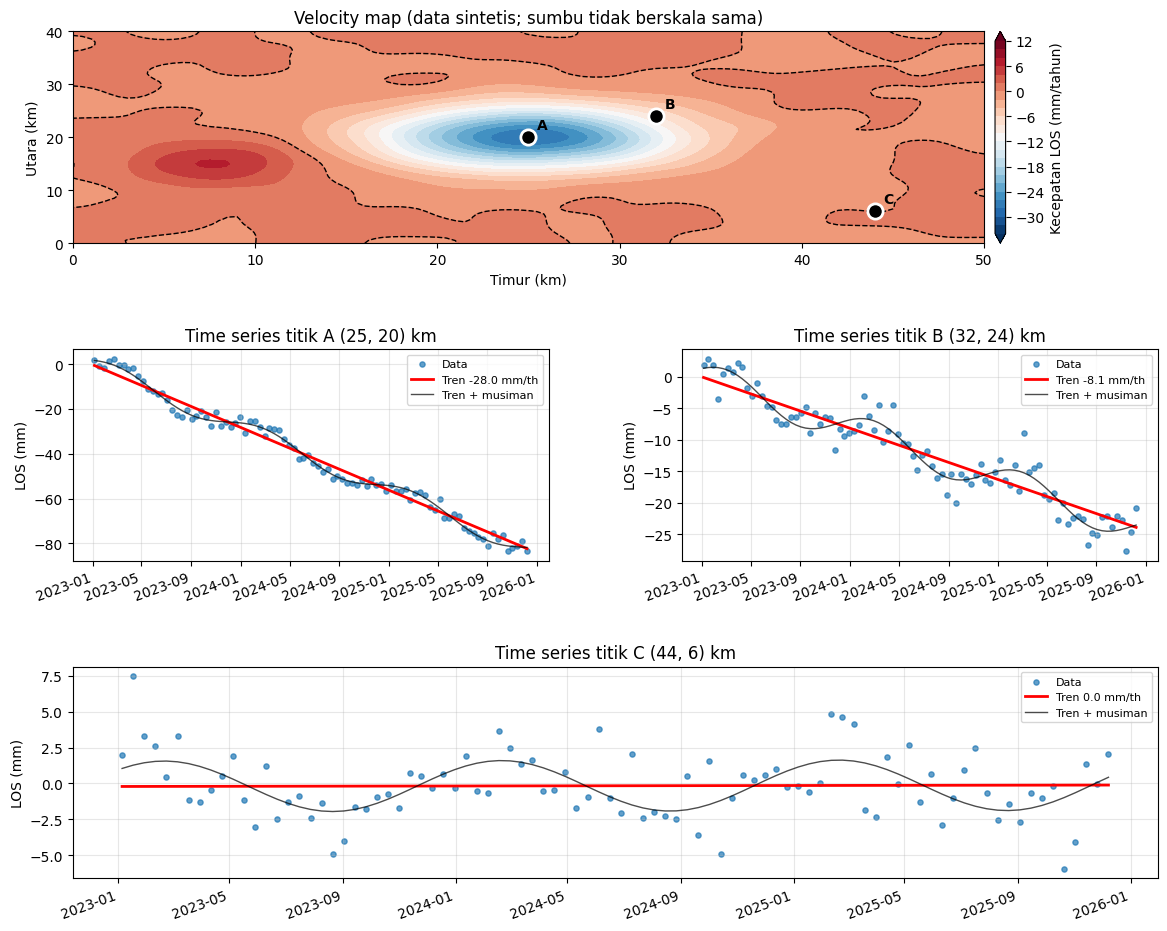

In [7]:
# ---------------- DATA SINTETIS: velocity map dan time series ----------------
rng = np.random.default_rng(SEED_DASAR + 3)
nx, ny = 101, 81
xk = np.linspace(0, 50, nx); yk = np.linspace(0, 40, ny)     # km
Xk, Yk = np.meshgrid(xk, yk)

v_benar = (-28 * np.exp(-(((Xk - 25) / 8) ** 2 + ((Yk - 20) / 6) ** 2) )
           + 6 * np.exp(-(((Xk - 8) / 5) ** 2 + ((Yk - 15) / 5) ** 2)))          # mm/tahun
vel_map = v_benar + gaussian_filter(rng.normal(size=Xk.shape), 3) * 4.0          # peta hasil estimasi (ada derau)

titik = {"A": (25, 20), "B": (32, 24), "C": (44, 6)}
sampel = lambda arr, p: arr[np.argmin(abs(yk - p[1])), np.argmin(abs(xk - p[0]))]

# epoch dan model time series: tren linear + musiman tahunan + derau
epoch = pd.date_range("2023-01-05", periods=90, freq="12D")
t = (epoch - epoch[0]).days.values / 365.25          # tahun
amp = {"A": 4.0, "B": 3.0, "C": 2.0}
ts = {k: sampel(v_benar, p) * t + amp[k] * np.sin(2 * np.pi * t + 0.6) + rng.normal(0, 2.0, t.size)
      for k, p in titik.items()}

# ---------------- OUTPUT: regresi tren + musiman (kuadrat terkecil) ----------------
G = np.column_stack([np.ones_like(t), t, np.sin(2 * np.pi * t), np.cos(2 * np.pi * t)])
hasil = {}
for k, d in ts.items():
    m, *_ = np.linalg.lstsq(G, d, rcond=None)
    res = d - G @ m
    s2 = res @ res / (len(d) - G.shape[1])
    cov = s2 * np.linalg.inv(G.T @ G)
    hasil[k] = dict(laju=m[1], se=np.sqrt(cov[1, 1]), musim=np.hypot(m[2], m[3]), rms=np.sqrt(np.mean(res ** 2)),
                    total=m[1] * t[-1], map=sampel(vel_map, titik[k]))

print(f"Epoch: {len(t)} | {epoch[0].date()} s.d. {epoch[-1].date()} | durasi {t[-1]:.2f} tahun")
print(f"Velocity map: min {vel_map.min():.1f}, maks {vel_map.max():.1f} mm/tahun\n")
tab = pd.DataFrame({
    "Titik": [f"{k} {titik[k]}" for k in hasil],
    "Laju time series (mm/th)": [f"{h['laju']:.1f} +/- {1.96*h['se']:.1f}" for h in hasil.values()],
    "Velocity map (mm/th)": [f"{h['map']:.1f}" for h in hasil.values()],
    "Total periode (mm)": [f"{h['total']:.0f}" for h in hasil.values()],
    "Amp. musiman (mm)": [f"{h['musim']:.1f}" for h in hasil.values()],
    "RMS residu (mm)": [f"{h['rms']:.1f}" for h in hasil.values()],
})
print(tab.to_string(index=False))

# ---------------- VERIFIKASI: laju time series vs velocity map pada titik yang sama ----------------
print("\nVERIFIKASI konsistensi grafik vs velocity map (selisih dalam mm/tahun):")
for k, h in hasil.items():
    print(f"  Titik {k}: selisih = {h['laju'] - h['map']:+.1f} | ketidakpastian time series (95%) = {1.96*h['se']:.1f}")

# ---------------- VISUALISASI ----------------
fig = plt.figure(figsize=(14, 11)); gs = GridSpec(3, 2, figure=fig, hspace=0.5, wspace=0.28)
ax = fig.add_subplot(gs[0, :])
im = ax.contourf(Xk, Yk, vel_map, levels=np.linspace(-34, 12, 24), cmap="RdBu_r", extend="both")
plt.colorbar(im, ax=ax, pad=0.01, label="Kecepatan LOS (mm/tahun)")
ax.contour(Xk, Yk, vel_map, levels=[0], colors="k", linestyles="--", linewidths=1)
for k, p in titik.items():
    ax.plot(*p, "o", ms=11, mfc="k", mec="w", mew=2); ax.annotate(k, p, xytext=(6, 6), textcoords="offset points", fontweight="bold")
ax.set_xlabel("Timur (km)"); ax.set_ylabel("Utara (km)"); ax.grid(False)
ax.set_title("Velocity map (data sintetis; sumbu tidak berskala sama)")
for (k, d), pos in zip(ts.items(), [gs[1, 0], gs[1, 1], gs[2, :]]):
    a = fig.add_subplot(pos); h = hasil[k]
    a.scatter(epoch, d, s=14, alpha=.7, label="Data")
    m, *_ = np.linalg.lstsq(G, d, rcond=None)
    a.plot(epoch, m[0] + m[1] * t, "r-", lw=2, label=f"Tren {h['laju']:.1f} mm/th")
    a.plot(epoch, G @ m, "k-", lw=1, alpha=.7, label="Tren + musiman")
    a.set_title(f"Time series titik {k} {titik[k]} km"); a.set_ylabel("LOS (mm)"); a.legend(fontsize=8)
    plt.setp(a.get_xticklabels(), rotation=20, ha="right")
plt.show()

### Interpretasi (ditulis sendiri berdasarkan keluaran di atas)

**Pengamatan dan dugaan:**
Velocity map menunjukkan satu zona penurunan LOS terpusat di sekitar (25, 20) km dengan kecepatan hingga −27,9 mm/tahun, serta zona kecil bergerak mendekati satelit (maksimum +6,2 mm/tahun) di sekitar (8, 15) km. Titik A bergerak −28,0 ± 0,5 mm/tahun (total sekitar −82 mm dalam 2,92 tahun), titik B di tepi zona −8,1 ± 0,5 mm/tahun (sekitar −24 mm), dan titik C 0,0 ± 0,5 mm/tahun sehingga relatif stabil dan layak dipertimbangkan sebagai titik referensi. Tren linear sudah menjelaskan sebagian besar perubahan (residu RMS 1,8–2,0 mm), dengan komponen musiman tahunan berpuncak 1,8–3,9 mm yang **diduga** terkait siklus hidrologi. Laju dari grafik cocok dengan velocity map pada ketiga titik (selisih ≤ 0,1 mm/tahun, di bawah ketidakpastian 0,5 mm/tahun). Penyebab penurunan (misalnya pengambilan air tanah atau pemadatan sedimen) hanya **dugaan** dan **tidak dapat ditentukan** tanpa data muka air tanah atau GNSS.

**Keterbatasan:** (1) semua nilai adalah LOS, bukan vertikal murni; (2) hanya model tren + musiman tahunan yang dicocokkan, perubahan laju yang tidak linear tidak diuji; (3) ketidakpastian yang dilaporkan hanya galat regresi (95%), belum memuat galat atmosfer dan referensi.

---
# STUDI KASUS 4: SEISMIK REFRAKSI
## Kurva Jarak-Waktu dan Model Dua Lapis (data sama dengan Tugas 1)

### Prompt (R–T–C–I–K–O–Q–V) dan uji kelengkapan

In [8]:
prompt_4 = """
### Role
Anda adalah geofisikawan teknik sipil yang berpengalaman dalam akuisisi dan
interpretasi seismik refraksi dua lapis.

### Task
Interpretasikan kurva waktu tempuh (travel time): jumlah lapisan, perbedaan kecepatan,
kedalaman batas lapisan, dan kemungkinan material.

### Context
Waktu tiba gelombang P pertama memuat informasi kecepatan dan kedalaman lapisan.
Survei untuk calon fondasi gedung dua lantai: satu lintasan lurus 44 m, 12 geophone
berspasi 4 m, sumber pukulan palu di ujung lintasan (forward shot).

### Input
x = [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44]            (m)
t = [0, 8, 16, 24, 29, 33, 37, 41, 45, 49, 53, 57]            (ms)

### Constraints
- Gunakan hanya data pada bagian Input; dilarang menambah atau mengubah titik data.
- Gunakan model dua lapis horizontal dengan metode jarak silang dan intercept time.
- Tampilkan rumus dan langkah hitung dengan satuan (m/s, m, ms).
- Hati-hati mengidentifikasi batuan hanya dari kecepatan; jika tidak didukung data,
  tulis "tidak dapat ditentukan".

### Output
1. Tabel: V1, V2, intercept time, jarak silang, kedalaman batas lapisan
2. Grafik jarak vs waktu tiba beserta garis fit tiap segmen
3. Interpretasi singkat (maksimal 5 kalimat)

### Quality Criteria
- Semua angka pada interpretasi dapat ditelusuri ke perhitungan.
- Satuan konsisten; ketidakpastian atau keterbatasan model disebutkan.

### Optional Verification
Hitung ulang kedalaman dengan metode intercept time dan jarak silang, lalu uji
sensitivitas terhadap kesalahan pembacaan waktu tiba.
"""
print(prompt_4)
print("-" * 70)
REKAP_PROMPT["4. Seismik Refraksi"] = cek_prompt(prompt_4)


### Role
Anda adalah geofisikawan teknik sipil yang berpengalaman dalam akuisisi dan
interpretasi seismik refraksi dua lapis.

### Task
Interpretasikan kurva waktu tempuh (travel time): jumlah lapisan, perbedaan kecepatan,
kedalaman batas lapisan, dan kemungkinan material.

### Context
Waktu tiba gelombang P pertama memuat informasi kecepatan dan kedalaman lapisan.
Survei untuk calon fondasi gedung dua lantai: satu lintasan lurus 44 m, 12 geophone
berspasi 4 m, sumber pukulan palu di ujung lintasan (forward shot).

### Input
x = [0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44]            (m)
t = [0, 8, 16, 24, 29, 33, 37, 41, 45, 49, 53, 57]            (ms)

### Constraints
- Gunakan hanya data pada bagian Input; dilarang menambah atau mengubah titik data.
- Gunakan model dua lapis horizontal dengan metode jarak silang dan intercept time.
- Tampilkan rumus dan langkah hitung dengan satuan (m/s, m, ms).
- Hati-hati mengidentifikasi batuan hanya dari kecepatan; jika tidak didukung data,
  

### Keluaran, verifikasi, dan grafik

SSE tiap kandidat titik pisah (s^2): {3: '6.22e-07', 4: '1.02e-33', 5: '3.60e-06', 6: '1.37e-05', 7: '2.67e-05', 8: '4.05e-05', 9: '5.39e-05'}
Titik pisah terpilih: 4 titik di segmen 1 (x = 0-12 m), 8 titik di segmen 2 (x = 16-44 m)

                 Parameter                            Rumus        Nilai
         V1 (lapisan atas)             1 / gradien segmen 1    500.0 m/s
        V2 (lapisan bawah)             1 / gradien segmen 2   1000.0 m/s
         Intercept time Ti    perpotongan segmen 2 di x = 0     13.00 ms
           Jarak silang xc       perpotongan segmen 1 dan 2      13.00 m
              Sudut kritis                      asin(V1/V2) 30.0 derajat
Kedalaman (intercept time) Ti*V1*V2 / (2*sqrt(V2^2 - V1^2))       3.75 m
  Kedalaman (jarak silang)     (xc/2)*sqrt((V2-V1)/(V2+V1))       3.75 m

VERIFIKASI 1 - konsistensi dengan Tugas 1 (V1=500, V2=1000 m/s, xc=13 m, z=3.75 m): SESUAI
   Catatan: kedua rumus kedalaman setara secara aljabar, sehingga ini uji ketelitian hitun


VERIFIKASI 2 - sensitivitas terhadap derau waktu tiba (sigma = 0,5 ms, 5000 simulasi)
 Besaran Rata-rata   Std      Rentang 95%
V1 (m/s)    500.26 10.58  479.71 - 521.33
V2 (m/s)   1000.41 19.04 964.39 - 1038.64
  xc (m)     13.01  0.59    11.87 - 14.20
   z (m)      3.76  0.19      3.40 - 4.12


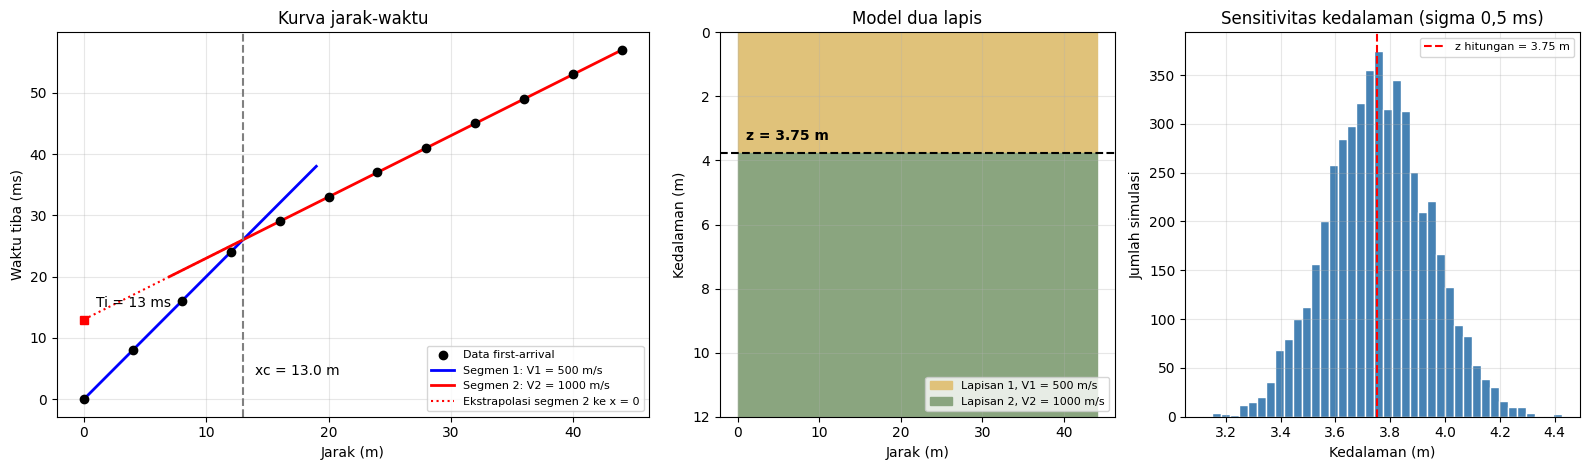

In [9]:
# ---------------- INPUT: data yang sama persis dengan Tugas 1 ----------------
x = np.array([0, 4, 8, 12, 16, 20, 24, 28, 32, 36, 40, 44], dtype=float)           # m
t = np.array([0, 8, 16, 24, 29, 33, 37, 41, 45, 49, 53, 57], dtype=float) / 1000   # s

# ---------------- OUTPUT 1: titik pisah dipilih oleh data (SSE minimum), bukan ditetapkan ----------------
def fit_dua_segmen(k, x, t):
    p1, p2 = np.polyfit(x[:k], t[:k], 1), np.polyfit(x[k:], t[k:], 1)
    sse = np.sum((np.polyval(p1, x[:k]) - t[:k]) ** 2) + np.sum((np.polyval(p2, x[k:]) - t[k:]) ** 2)
    return sse, p1, p2

kandidat = {k: fit_dua_segmen(k, x, t)[0] for k in range(3, len(x) - 2)}     # tiap segmen minimal 3 titik
k_opt = min(kandidat, key=kandidat.get)
print("SSE tiap kandidat titik pisah (s^2):", {k: f"{v:.2e}" for k, v in kandidat.items()})
print(f"Titik pisah terpilih: {k_opt} titik di segmen 1 (x = {x[0]:.0f}-{x[k_opt-1]:.0f} m), "
      f"{len(x)-k_opt} titik di segmen 2 (x = {x[k_opt]:.0f}-{x[-1]:.0f} m)\n")

def hitung(x, t, k):
    _, p1, p2 = fit_dua_segmen(k, x, t)
    V1, V2 = 1 / p1[0], 1 / p2[0]
    Ti = p2[1]
    xc = (p2[1] - p1[1]) / (p1[0] - p2[0])
    z_ti = Ti * V1 * V2 / (2 * np.sqrt(V2 ** 2 - V1 ** 2))
    z_xc = (xc / 2) * np.sqrt((V2 - V1) / (V2 + V1))
    return V1, V2, Ti, xc, z_ti, z_xc, p1, p2

V1, V2, Ti, xc, z_ti, z_xc, p1, p2 = hitung(x, t, k_opt)
theta_c = np.degrees(np.arcsin(V1 / V2))
hasil = pd.DataFrame({
    "Parameter": ["V1 (lapisan atas)", "V2 (lapisan bawah)", "Intercept time Ti", "Jarak silang xc",
                  "Sudut kritis", "Kedalaman (intercept time)", "Kedalaman (jarak silang)"],
    "Rumus": ["1 / gradien segmen 1", "1 / gradien segmen 2", "perpotongan segmen 2 di x = 0",
              "perpotongan segmen 1 dan 2", "asin(V1/V2)", "Ti*V1*V2 / (2*sqrt(V2^2 - V1^2))",
              "(xc/2)*sqrt((V2-V1)/(V2+V1))"],
    "Nilai": [f"{V1:.1f} m/s", f"{V2:.1f} m/s", f"{Ti*1000:.2f} ms", f"{xc:.2f} m", f"{theta_c:.1f} derajat",
              f"{z_ti:.2f} m", f"{z_xc:.2f} m"],
})
print(hasil.to_string(index=False))

# ---------------- VERIFIKASI 1: cocok dengan hitungan Tugas 1 ----------------
print("\nVERIFIKASI 1 - konsistensi dengan Tugas 1 (V1=500, V2=1000 m/s, xc=13 m, z=3.75 m):",
      "SESUAI" if np.allclose([V1, V2, xc, z_ti], [500, 1000, 13, 3.7528], atol=0.01) else "TIDAK SESUAI")
print("   Catatan: kedua rumus kedalaman setara secara aljabar, sehingga ini uji ketelitian hitung,")
print("   bukan pembuktian independen. Pembuktian independen memerlukan data bor atau reverse shot.")

# ---------------- VERIFIKASI 2: uji sensitivitas kesalahan baca waktu tiba (Monte Carlo) ----------------
rng = np.random.default_rng(SEED_DASAR + 4)
sim = []
for _ in range(5000):
    tn = t + rng.normal(0, 0.0005, t.size); tn[0] = 0.0          # sigma 0,5 ms; t(0) tetap 0
    r = hitung(x, tn, k_opt); sim.append([r[0], r[1], r[3], r[4]])
sim = np.array(sim)
print("\nVERIFIKASI 2 - sensitivitas terhadap derau waktu tiba (sigma = 0,5 ms, 5000 simulasi)")
sens = pd.DataFrame({
    "Besaran": ["V1 (m/s)", "V2 (m/s)", "xc (m)", "z (m)"],
    "Rata-rata": [f"{c.mean():.2f}" for c in sim.T],
    "Std": [f"{c.std():.2f}" for c in sim.T],
    "Rentang 95%": [f"{np.percentile(c,2.5):.2f} - {np.percentile(c,97.5):.2f}" for c in sim.T],
})
print(sens.to_string(index=False))

# ---------------- VISUALISASI ----------------
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
a = ax[0]; a.scatter(x, t * 1000, c="k", zorder=5, label="Data first-arrival")
x1 = np.linspace(0, xc + 6, 50); x2 = np.linspace(xc - 6, 44, 50)
a.plot(x1, np.polyval(p1, x1) * 1000, "b-", lw=2, label=f"Segmen 1: V1 = {V1:.0f} m/s")
a.plot(x2, np.polyval(p2, x2) * 1000, "r-", lw=2, label=f"Segmen 2: V2 = {V2:.0f} m/s")
a.plot([0, xc], np.polyval(p2, [0, xc]) * 1000, "r:", lw=1.5, label="Ekstrapolasi segmen 2 ke x = 0")
a.axvline(xc, ls="--", c="gray"); a.annotate(f"xc = {xc:.1f} m", (xc, 4), xytext=(xc + 1, 4))
a.plot(0, Ti * 1000, "rs"); a.annotate(f"Ti = {Ti*1000:.0f} ms", (0, Ti * 1000), xytext=(1, Ti * 1000 + 2))
a.set_xlabel("Jarak (m)"); a.set_ylabel("Waktu tiba (ms)"); a.set_title("Kurva jarak-waktu"); a.legend(fontsize=8)
a = ax[1]; xs = np.linspace(0, 44, 10)
a.fill_between(xs, 0, z_ti, color="#e0c27a", label=f"Lapisan 1, V1 = {V1:.0f} m/s")
a.fill_between(xs, z_ti, 12, color="#8aa57f", label=f"Lapisan 2, V2 = {V2:.0f} m/s")
a.axhline(z_ti, c="k", ls="--"); a.text(1, z_ti - 0.4, f"z = {z_ti:.2f} m", fontweight="bold")
a.set_ylim(12, 0); a.set_xlabel("Jarak (m)"); a.set_ylabel("Kedalaman (m)"); a.set_title("Model dua lapis"); a.legend(fontsize=8, loc="lower right")
a = ax[2]; a.hist(sim[:, 3], bins=40, color="steelblue", edgecolor="white")
a.axvline(z_ti, c="r", ls="--", label=f"z hitungan = {z_ti:.2f} m"); a.set_xlabel("Kedalaman (m)"); a.set_ylabel("Jumlah simulasi")
a.set_title("Sensitivitas kedalaman (sigma 0,5 ms)"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

### Interpretasi (ditulis sendiri berdasarkan keluaran di atas)

**Interpretasi singkat (maksimal 5 kalimat):**
Data mendukung dua segmen linear dengan titik pisah di antara x = 12 dan 16 m (SSE minimum), sehingga model dua lapis horizontal dapat diterima: V1 = 500 m/s dan V2 = 1000 m/s. Intercept time 13 ms dan jarak silang 13 m menghasilkan kedalaman batas lapisan 3,75 m pada kedua metode, dengan rentang 3,40–4,12 m (95%) bila waktu tiba mengandung galat baca 0,5 ms. Hasil ini sama persis dengan hitungan Tugas 1, jadi hitungan tersebut terkonfirmasi. V1 = 500 m/s sesuai dengan material lepas/tanah, sedangkan V2 = 1000 m/s menunjukkan material yang lebih padat, jenuh, atau lapuk, tetapi nilainya tidak cukup untuk memastikan batuan dasar sehingga jenis materialnya **tidak dapat ditentukan** (istilah "batuan dasar" pada prompt sebaiknya dibaca sebagai "lapisan lebih padat"). Dengan satu *forward shot*, kemiringan batas dan variasi lateral **tidak dapat ditentukan**.

**Keterbatasan:** (1) kedua rumus kedalaman setara secara aljabar, jadi kecocokannya adalah uji ketelitian hitung, bukan bukti independen (perlu data bor atau *reverse shot*); (2) kedalaman 3,75 m lebih kecil dari satu spasi geophone (4 m) dan segmen 1 hanya berisi 4 titik sehingga V1 kurang terkunci; (3) data ilustrasi tanpa derau nyata, sehingga sensitivitas dihitung dengan simulasi.

---
# STUDI KASUS 5: GRAVITASI
## Interpretasi Peta Anomali Bouguer

### Prompt (R–T–C–I–K–O–Q–V) dan uji kelengkapan

In [10]:
prompt_5 = """
### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil analisis gravitasi
(anomali Bouguer) untuk pemetaan struktur bawah permukaan.

### Task
Interpretasikan pola anomali gravitasi: zona anomali positif dan negatif, kemungkinan
perubahan densitas, dan kemungkinan struktur geologi.

### Context
Gravitasi memperlihatkan perbedaan densitas bawah permukaan melalui perubahan medan
gravitasi. Nilai anomali bersifat relatif terhadap referensi yang dipakai, sehingga tanda
positif/negatif harus dibaca terhadap sekelilingnya.

### Input
Peta Complete Bouguer Anomaly (mGal), area 100 km x 80 km, grid 1 km. Informasi geologi:
dugaan cekungan sedimen di bagian barat dan batuan beku di bagian timur.

### Constraints
- Dilarang mengolah ulang data atau menghitung ulang densitas.
- Tidak boleh langsung menentukan jenis batuan dari nilai anomali (solusi tidak unik).
- Bedakan pengamatan pola dari dugaan struktur geologi.
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapat ditentukan".

### Output
1. Tabel zona anomali positif/negatif (posisi, nilai ekstrem, luas)
2. Lokasi gradien tajam yang menandai kemungkinan batas struktur
3. Interpretasi singkat (maksimal 5 kalimat) dan daftar keterbatasan

### Quality Criteria
- Interpretasi berbasis pola anomali dan didukung informasi geologi.
- Satuan konsisten (mGal, km, mGal/km).

### Optional Verification
Cocokkan interpretasi dengan peta gravitasi, peta geologi, dan data geofisika lain
(seismik, magnetik) atau data sumur.
"""
print(prompt_5)
print("-" * 70)
REKAP_PROMPT["5. Gravitasi"] = cek_prompt(prompt_5)


### Role
Anda adalah geofisikawan yang mendampingi interpretasi hasil analisis gravitasi
(anomali Bouguer) untuk pemetaan struktur bawah permukaan.

### Task
Interpretasikan pola anomali gravitasi: zona anomali positif dan negatif, kemungkinan
perubahan densitas, dan kemungkinan struktur geologi.

### Context
Gravitasi memperlihatkan perbedaan densitas bawah permukaan melalui perubahan medan
gravitasi. Nilai anomali bersifat relatif terhadap referensi yang dipakai, sehingga tanda
positif/negatif harus dibaca terhadap sekelilingnya.

### Input
Peta Complete Bouguer Anomaly (mGal), area 100 km x 80 km, grid 1 km. Informasi geologi:
dugaan cekungan sedimen di bagian barat dan batuan beku di bagian timur.

### Constraints
- Dilarang mengolah ulang data atau menghitung ulang densitas.
- Tidak boleh langsung menentukan jenis batuan dari nilai anomali (solusi tidak unik).
- Bedakan pengamatan pola dari dugaan struktur geologi.
- Jika data tidak mendukung suatu kesimpulan, tulis "tidak dapat 

### Keluaran, verifikasi, dan grafik

Median peta (acuan relatif) = -2.5 mGal | rentang -29.4 s.d. 28.2 mGal
                       Zona Puncak (E, N km) Nilai ekstrem (mGal) Luas (km2)
Negatif (< median - 8 mGal)         (25, 38)                -28.3       1025
Positif (> median + 8 mGal)         (72, 52)                +26.0        633

GRADIEN HORIZONTAL
  Profil y = 10 km (jauh dari anomali utama): gradien |dg/dx| maks = 0.92 mGal/km di x = 50 km
  Gradien rata-rata sepanjang x = 50 km (y = 0-80): 0.94 mGal/km
  Gradien rata-rata seluruh peta                  : 0.32 mGal/km
  Sepanjang x = 50 km: min 0.79, maks 1.26 mGal/km -> menerus (kriteria: min > 2x rata-rata peta)
  Perubahan nilai melintasi x = 44 -> 56 km pada y = 10 km: +7.7 mGal
  Gradien maks pada flank (bukan sesar): cekungan 1.40, intrusi 2.18 mGal/km
  Profil y = 38 km: nilai min -29.4 mGal (x = 25), maks 6.4 mGal (x = 74)

VERIFIKASI terhadap model sintetis (kunci jawaban)
  Pusat cekungan  : terdeteksi (25, 38) | model (25, 38)
  Pusat intrusi   : terde

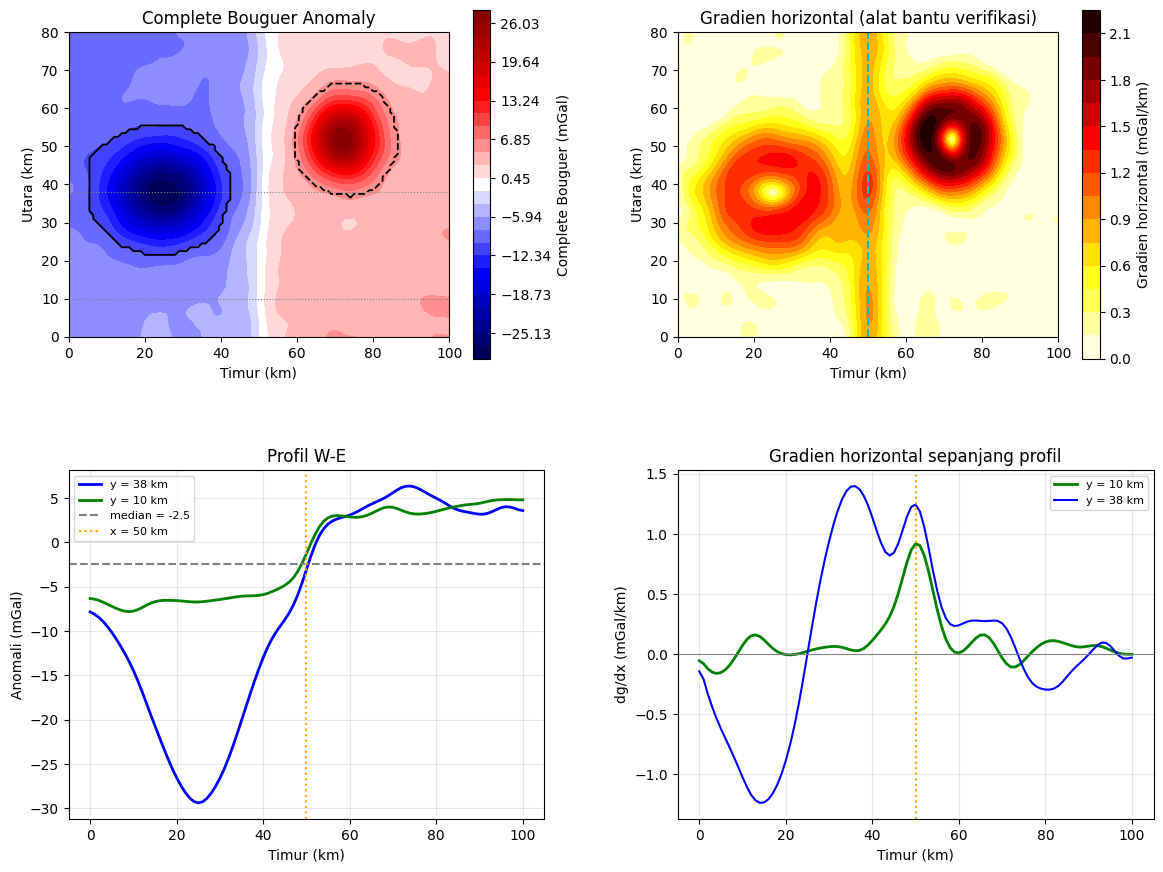

In [11]:
# ---------------- DATA SINTETIS: Complete Bouguer Anomaly ----------------
rng = np.random.default_rng(SEED_DASAR + 5)
xg = np.arange(0, 101.0); yg = np.arange(0, 81.0)           # km, grid 1 km
Xg, Yg = np.meshgrid(xg, yg)

cekungan = -22 * np.exp(-(((Xg - 25) / 14) ** 2 + ((Yg - 38) / 12) ** 2) / 1)
intrusi  =  26 * np.exp(-(((Xg - 72) / 9) ** 2 + ((Yg - 52) / 10) ** 2) / 1)
sesar    =  4.0 * np.tanh((Xg - 50) / 4)                       # undak landai di x = 50 km
regional = 0.04 * Xg - 0.03 * Yg - 3
bg = cekungan + intrusi + sesar + regional + gaussian_filter(rng.normal(size=Xg.shape), 2.5) * 3.0   # mGal

# ---------------- OUTPUT 1: zona anomali (dibaca terhadap median peta, bukan terhadap nol mutlak) ----------------
med = np.median(bg)
halus = gaussian_filter(bg, 2)
def zona(mask, nama):
    lab, n = ndimage.label(mask); k = np.argmax(ndimage.sum(mask, lab, range(1, n + 1))) + 1; m = lab == k
    sub = np.where(m, halus, np.nan)
    iy, ix = np.unravel_index(np.nanargmax(np.abs(sub - med)), sub.shape)
    return {"Zona": nama, "Puncak (E, N km)": f"({xg[ix]:.0f}, {yg[iy]:.0f})", "Nilai ekstrem (mGal)": f"{halus[iy, ix]:+.1f}",
            "Luas (km2)": f"{m.sum():.0f}"}, m
z_neg, m_neg = zona(halus < med - 8, f"Negatif (< median - 8 mGal)")
z_pos, m_pos = zona(halus > med + 8, f"Positif (> median + 8 mGal)")
print(f"Median peta (acuan relatif) = {med:.1f} mGal | rentang {bg.min():.1f} s.d. {bg.max():.1f} mGal")
print(pd.DataFrame([z_neg, z_pos]).to_string(index=False))

# ---------------- OUTPUT 2: gradien horizontal ----------------
gy, gx = np.gradient(halus)                  # mGal/km (grid 1 km)
hgm = np.hypot(gx, gy)
ip = np.argmin(abs(yg - 10))                  # profil W-E yang jauh dari cekungan dan intrusi
xmax = xg[np.argmax(np.abs(gx[ip, :]))]
print(f"\nGRADIEN HORIZONTAL")
print(f"  Profil y = 10 km (jauh dari anomali utama): gradien |dg/dx| maks = {np.abs(gx[ip,:]).max():.2f} mGal/km di x = {xmax:.0f} km")
print(f"  Gradien rata-rata sepanjang x = 50 km (y = 0-80): {np.abs(gx[:, 50]).mean():.2f} mGal/km")
print(f"  Gradien rata-rata seluruh peta                  : {np.abs(gx).mean():.2f} mGal/km")
g50 = np.abs(gx[:, 50])
print(f"  Sepanjang x = 50 km: min {g50.min():.2f}, maks {g50.max():.2f} mGal/km -> {'menerus' if g50.min() > 2*np.abs(gx).mean() else 'tidak menerus'} (kriteria: min > 2x rata-rata peta)")
print(f"  Perubahan nilai melintasi x = 44 -> 56 km pada y = 10 km: {halus[ip, 56] - halus[ip, 44]:+.1f} mGal")
print(f"  Gradien maks pada flank (bukan sesar): cekungan {np.abs(gx[:, :45]).max():.2f}, intrusi {np.abs(gx[:, 58:]).max():.2f} mGal/km")
i40 = np.argmin(abs(yg - 38))
print(f"  Profil y = 38 km: nilai min {bg[i40].min():.1f} mGal (x = {xg[bg[i40].argmin()]:.0f}), maks {bg[i40].max():.1f} mGal (x = {xg[bg[i40].argmax()]:.0f})")

# ---------------- VERIFIKASI terhadap model sintetis ----------------
print("\nVERIFIKASI terhadap model sintetis (kunci jawaban)")
print(f"  Pusat cekungan  : terdeteksi {z_neg['Puncak (E, N km)']} | model (25, 38)")
print(f"  Pusat intrusi   : terdeteksi {z_pos['Puncak (E, N km)']} | model (72, 52)")
print(f"  Posisi undak    : terdeteksi x = {xmax:.0f} km | model x = 50 km")

# ---------------- VISUALISASI ----------------
fig = plt.figure(figsize=(14, 10.5)); gs = GridSpec(2, 2, figure=fig, hspace=0.32, wspace=0.28)
a = fig.add_subplot(gs[0, 0]); im = a.contourf(Xg, Yg, bg, levels=np.linspace(bg.min(), bg.max(), 28), cmap="seismic")
plt.colorbar(im, ax=a, label="Complete Bouguer (mGal)"); a.contour(Xg, Yg, m_neg.astype(float), [0.5], colors="k", linewidths=1.3)
a.contour(Xg, Yg, m_pos.astype(float), [0.5], colors="k", linewidths=1.3, linestyles="--")
a.axhline(38, color="gray", lw=.8, ls=":"); a.axhline(10, color="gray", lw=.8, ls=":")
a.set_title("Complete Bouguer Anomaly"); a.set_xlabel("Timur (km)"); a.set_ylabel("Utara (km)"); a.set_aspect("equal"); a.grid(False)
a = fig.add_subplot(gs[0, 1]); im = a.contourf(Xg, Yg, hgm, levels=20, cmap="hot_r")
plt.colorbar(im, ax=a, label="Gradien horizontal (mGal/km)"); a.axvline(50, color="c", ls="--", lw=1.5)
a.set_title("Gradien horizontal (alat bantu verifikasi)"); a.set_xlabel("Timur (km)"); a.set_ylabel("Utara (km)"); a.set_aspect("equal"); a.grid(False)
a = fig.add_subplot(gs[1, 0])
a.plot(xg, bg[i40], "b-", lw=2, label="y = 38 km"); a.plot(xg, bg[ip], "g-", lw=2, label="y = 10 km")
a.axhline(med, color="gray", ls="--", label=f"median = {med:.1f}"); a.axvline(50, color="orange", ls=":", label="x = 50 km")
a.set_xlabel("Timur (km)"); a.set_ylabel("Anomali (mGal)"); a.set_title("Profil W-E"); a.legend(fontsize=8)
a = fig.add_subplot(gs[1, 1]); a.plot(xg, gx[ip], "g-", lw=2, label="y = 10 km"); a.plot(xg, gx[i40], "b-", lw=1.5, label="y = 38 km")
a.axvline(50, color="orange", ls=":"); a.axhline(0, color="gray", lw=.8)
a.set_xlabel("Timur (km)"); a.set_ylabel("dg/dx (mGal/km)"); a.set_title("Gradien horizontal sepanjang profil"); a.legend(fontsize=8)
plt.show()

### Interpretasi (ditulis sendiri berdasarkan keluaran di atas)

**Pengamatan dan dugaan:**
Terdapat dua zona anomali utama relatif terhadap median peta (−2,5 mGal): anomali negatif berpuncak −28,3 mGal di (25, 38) km (sekitar 1025 km²) di barat, dan anomali positif berpuncak +26,0 mGal di (72, 52) km (sekitar 633 km²) di timur, yang sejalan dengan informasi geologi umum (cekungan sedimen di barat dan batuan beku di timur). Perubahan densitas diduga **menurun** di zona negatif dan **meningkat** di zona positif relatif sekitarnya, tetapi jenis batuan **tidak dapat ditentukan** karena solusi gravitasi tidak unik (kedalaman dan densitas saling tukar). Lineasi gradien utara-selatan menerus di x ≈ 50 km (0,79–1,26 mGal/km sepanjang y = 0–80 km, sedangkan rata-rata peta 0,32 mGal/km) dengan perubahan sekitar +7,7 mGal antara x = 44 dan 56 km pada y = 10 km, yang **diduga** batas struktur (sesar atau kontak formasi) dan belum dapat dibedakan dari kontak litologi. Gradien lebih besar di tepi cekungan (1,40 mGal/km) dan intrusi (2,18 mGal/km) menandai batas tubuh anomali itu sendiri, bukan sesar.

**Verifikasi:** pusat kedua anomali dan posisi undak (x = 50 km) tepat sama dengan model sintetis. Pada data nyata perlu dicocokkan dengan peta geologi, seismik, atau magnetik.

**Keterbatasan:** (1) nilai anomali relatif terhadap referensi, bukan nilai absolut; (2) pemisahan regional-residual tidak dilakukan karena prompt melarang pengolahan ulang; (3) ambang ±8 mGal dari median adalah pilihan saya sehingga luas zona bergantung padanya.

---
# REKAP DAN PENUTUP

In [12]:
# ---------------- REKAP: kelengkapan kelima prompt ----------------
rekap = pd.DataFrame([{"Studi kasus": k, "Skor wajib (R,T,C,I,K,O,Q)": f"{s}/7", "Verification": "ada" if v else "tidak ada"}
                      for k, (s, v) in REKAP_PROMPT.items()])
print(rekap.to_string(index=False))
print("\nCatatan: pengecek hanya memeriksa keberadaan kata kunci, bukan mutu isi (sama seperti catatan di Tugas 1).")

         Studi kasus Skor wajib (R,T,C,I,K,O,Q) Verification
       1. Geolistrik                        7/7          ada
           2. DInSAR                        7/7          ada
3. InSAR Time Series                        7/7          ada
 4. Seismik Refraksi                        7/7          ada
        5. Gravitasi                        7/7          ada

Catatan: pengecek hanya memeriksa keberadaan kata kunci, bukan mutu isi (sama seperti catatan di Tugas 1).


## Penutup

**Hasil kelengkapan prompt.** Kelima prompt memperoleh skor 7/7 pada komponen wajib dan memuat *Verification*. Seperti catatan di Tugas 1, skor ini hanya memeriksa keberadaan kata kunci, bukan mutu isi.

**Peran Constraints.** Kalimat "tidak dapat ditentukan" benar-benar terpakai: jenis batuan (kasus 1, 4, 5), mekanisme sesar (kasus 2), penyebab penurunan tanah (kasus 3), dan kemiringan batas lapisan (kasus 4). Pada kasus 2 batasan "tidak semua perubahan warna adalah deformasi" terbukti penting: sekitar 721 km² area melewati ambang derau tetapi bukan deformasi.

**Verifikasi.** Karena modelnya sintetis, hasil deteksi dapat dicocokkan dengan kunci jawaban (kasus 1, 2, 3, 5), sedangkan kasus 4 dicocokkan dengan hitungan Tugas 1 dan diuji sensitivitasnya. Pada data lapangan, kunci jawaban semacam ini tidak ada, sehingga verifikasi harus datang dari data pembanding (bor, GNSS, geologi).

**Catatan jujur.** Semua data di sini adalah data ilustrasi, bukan data lapangan. Interpretasi pada kasus nyata harus memakai data pembanding sebelum dijadikan kesimpulan.